# 02. 모델 학습 결과 — 학습 데이터 교차검증

학습은 `scripts/train.py`(M0, M1)와 `scripts/train_cnn.py`(M2)가 한다. 이 노트북은 저장된 결과만 읽어 정리한다.
평가 데이터는 쓰지 않았다.

- 교차검증: 로트 단위 5-fold (`StratifiedGroupKFold`)
- M2는 학습 시간 때문에 fold 0 하나로만 검증하고, 거기서 멈출 에폭을 정했다 (PROTOCOL.md 4절)

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORT_DIR, FIG_DIR = ROOT / "reports", ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid")

decisions = json.loads((REPORT_DIR / "decisions.json").read_text())
cv = pd.read_csv(REPORT_DIR / "cv_results.csv")
per_class = pd.read_csv(REPORT_DIR / "cv_per_class.csv", index_col=0)
history = pd.read_csv(REPORT_DIR / "cnn_history.csv")
decisions

{'m0': '고정 설정',
 'm1_params': {'num_leaves': 31, 'min_child_samples': 20},
 'cv_macro_f1': {'M0': 0.483781112626013,
  'M1': 0.9142921946518833,
  'M2_fold0': 0.9360232353310357},
 'cnn_best_epoch': 23}

## 1. 교차검증 매크로 F1

In [2]:
cv.round(3)

,model,setting,fold0,fold1,fold2,fold3,fold4,mean
0,M0 크기 기준선,-,0.466,0.481,0.502,0.522,0.448,0.484
1,M1 특징 모델,"{""num_leaves"": 15, ""min_child_samples"": 20}",0.908,0.920,0.923,0.898,0.915,0.913
2,M1 특징 모델,"{""num_leaves"": 15, ""min_child_samples"": 50}",0.907,0.923,0.924,0.898,0.918,0.914
3,M1 특징 모델,"{""num_leaves"": 31, ""min_child_samples"": 20}",0.909,0.921,0.929,0.900,0.913,0.914
4,M1 특징 모델,"{""num_leaves"": 31, ""min_child_samples"": 50}",0.913,0.926,0.931,0.891,0.910,0.914


In [3]:
m1_setting = json.dumps(decisions["m1_params"])
m1_row = cv[cv.setting == m1_setting].iloc[0]
summary = pd.DataFrame({
    "fold 0": [cv.iloc[0].fold0, m1_row.fold0, decisions["cv_macro_f1"]["M2_fold0"]],
    "5-fold 평균": [cv.iloc[0]["mean"], m1_row["mean"], None],
}, index=["M0 크기 기준선", "M1 특징 모델", "M2 CNN"])
summary.round(3)

,fold 0,5-fold 평균
M0 크기 기준선,0.466,0.484
M1 특징 모델,0.909,0.914
M2 CNN,0.936,NaN


**해석**
- **M0 0.48 → M1 0.91**: 크기만 볼 때보다 모양 특징을 넣으면 크게 오른다. 패턴 분류에 모양 정보가 핵심이라는 뜻이다.
- M1의 설정 4가지는 0.913~0.914로 사실상 같다. 계획서대로 평균이 가장 높은 `num_leaves=31, min_child_samples=20`을 골랐다.
- **같은 fold 0 기준으로 M1 0.909, M2 0.936**. 다만 M2의 0.936은 fold 0에서 가장 좋았던 에폭을 고른 값이라 **낙관적**이다. 같은 fold로 에폭을 고르고 점수도 쟀기 때문이다. 공정한 비교는 평가 데이터에서 한다.

## 2. 패턴별 F1

,M0,M1,M2 (fold 0 only)
Center,0.799,0.979,0.970
Donut,0.497,0.850,0.889
Edge-Loc,0.484,0.897,0.903
Edge-Ring,0.937,0.991,0.992
Loc,0.227,0.841,0.848
Near-full,0.003,0.897,0.957
Random,0.357,0.929,0.929
Scratch,0.202,0.851,0.943
none,0.828,0.993,0.995


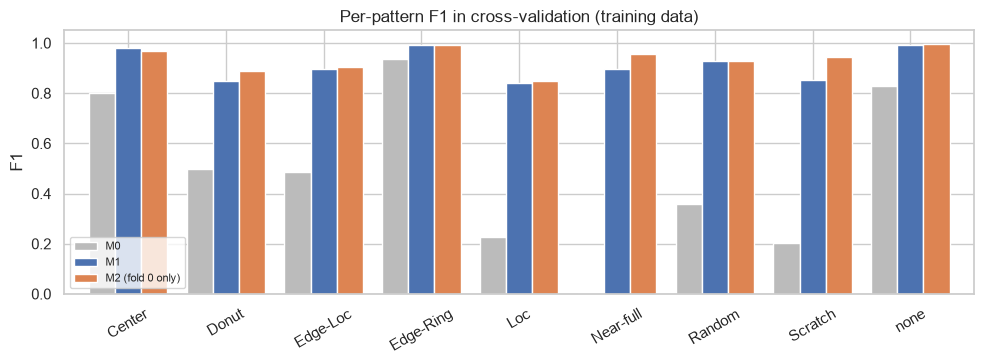

In [4]:
order = ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Near-full", "Random", "Scratch", "none"]
plot = per_class.reindex(order).rename(columns={"M2 (fold 0)": "M2 (fold 0 only)"})
fig, ax = plt.subplots(figsize=(10, 3.8))
plot.plot.bar(ax=ax, color=["#BBBBBB", "#4C72B0", "#DD8452"], width=0.8, rot=30)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1"); ax.set_title("Per-pattern F1 in cross-validation (training data)")
ax.legend(loc="lower left", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "06_cv_per_class.png", dpi=150)
plot.round(3)

**해석**
- M0는 `Edge-Ring`(0.94), `none`(0.83), `Center`(0.80)를 크기만으로 맞힌다. 크기 지름길이 통하는 패턴들이다. `Near-full`은 0이다.
- M1과 M2의 차이가 가장 큰 패턴은 **Scratch(0.85 → 0.94)** 와 **Near-full(0.90 → 0.96)** 이다.
  Scratch는 휘거나 끊긴 선이라 "가장 큰 덩어리의 길쭉함" 같은 사람이 만든 특징으로는 다 잡히지 않는다. EDA에서 예상한 대로 CNN이 나을 수 있는 곳이다.
- **Loc(0.84)** 과 **Donut(0.85~0.89)** 은 두 모델 모두 상대적으로 낮다. Loc은 Edge-Loc과 위치만 다르고, Donut은 Center와 헷갈리기 쉽다.
- M2는 fold 0 하나의 값이라 M1(5-fold 전체 예측)과 표본이 다르다. 참고로만 본다.

## 3. CNN 학습 곡선

,epoch,train_loss,val_macro_f1
20,21,0.122,0.927
21,22,0.129,0.813
22,23,0.122,0.936
23,24,0.127,0.916
24,25,0.118,0.724
25,26,0.113,0.931
26,27,0.113,0.919
27,28,0.108,0.890


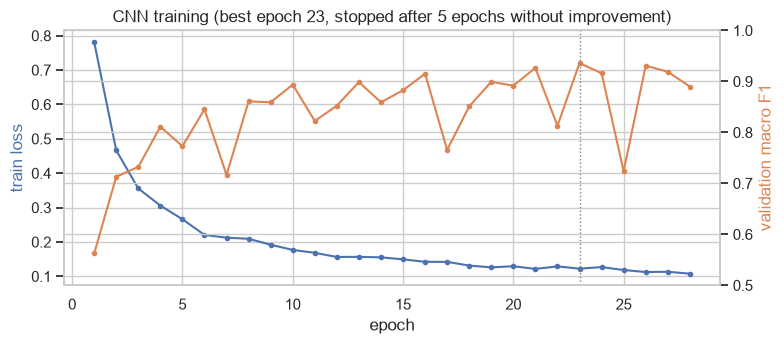

In [5]:
fig, ax1 = plt.subplots(figsize=(8, 3.6))
ax1.plot(history.epoch, history.train_loss, "o-", color="#4C72B0", ms=3, label="train loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("train loss", color="#4C72B0")
ax2 = ax1.twinx()
ax2.plot(history.epoch, history.val_macro_f1, "o-", color="#DD8452", ms=3, label="validation macro F1 (fold 0)")
ax2.axvline(decisions["cnn_best_epoch"], color="gray", ls=":", lw=1)
ax2.set_ylabel("validation macro F1", color="#DD8452"); ax2.set_ylim(0.5, 1.0)
ax1.set_title(f"CNN training (best epoch {decisions['cnn_best_epoch']}, stopped after 5 epochs without improvement)")
fig.tight_layout(); fig.savefig(FIG_DIR / "07_cnn_history.png", dpi=150)
history.round(3).tail(8)

**해석**
- 학습 손실(파란 선)은 꾸준히 내려간다.
- 검증 매크로 F1(주황 선)은 **에폭마다 0.72~0.94로 크게 흔들린다**. 이유로 보이는 것
  - 검증 fold의 `Near-full`이 11개 안팎이라, 몇 개만 맞히거나 틀려도 그 패턴 F1이 크게 변하고 매크로 F1의 1/9을 차지한다.
  - 학습률을 끝까지 고정해서, 후반에도 가중치가 크게 움직인다.
- 계획서대로 23에폭(가장 좋았던 지점)에서 멈추고, 최종 모델은 학습 데이터 전체로 23에폭 학습했다.
  점수가 이렇게 흔들리면 최종 모델의 23에폭이 좋은 지점이라는 보장이 없다. **이 불안정성은 결과 해석 때 한계로 적는다.**
- 다시 한다면: 학습률을 점점 줄이는 스케줄, 여러 seed의 평균, 마지막 몇 에폭 가중치 평균 등을 고려할 수 있다. 이번에는 계획서에 없으므로 바꾸지 않는다.

## 4. 고정한 결정

| 항목 | 값 |
|---|---|
| M0 | 고정 설정 (튜닝 없음) |
| M1 | `num_leaves=31`, `min_child_samples=20` |
| M2 | 23에폭, 학습 데이터 전체로 학습한 가중치 `models/cnn_final.pt` |

이 결정과 CNN 가중치를 평가 데이터를 열기 전에 커밋한다.